In [897]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


class Neural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        
        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat
    
    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))
    
    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)
    
    def relu(self, z):
        return np.maximum(0, z)
    
    def reluPrime(self,z):
        return 1 * (z > 0)

    def costFunctionPrimeRelu(self, X, y):
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.reluPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def forwardRelu(self,X):
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.relu(self.z3)
        return yHat

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J

    def costFunctionRelu(self, X,y):
        self.yHat=self.forwardRelu(X)
        J=0.5*sum((y-self.yHat)**2)
        return J
    
    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.sigmoidPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2


In [898]:
X=np.array(([3,5],[5,1],[10,1]),dtype=float)
y=np.array(([75],[80],[93]),dtype=float)

In [899]:
X


array([[ 3.,  5.],
       [ 5.,  1.],
       [10.,  1.]])

In [900]:
y

array([[75.],
       [80.],
       [93.]])

In [901]:
X=X/np.amax(X,axis=0)
y=y/100

In [902]:
X,y


(array([[0.3, 1. ],
        [0.5, 0.2],
        [1. , 0.2]]),
 array([[0.75],
        [0.8 ],
        [0.93]]))

In [903]:
NN=Neural_Network()

In [904]:
yH=NN.forward(X)

In [905]:
yH

array([[0.66039039],
       [0.6552387 ],
       [0.66725718]])

In [906]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

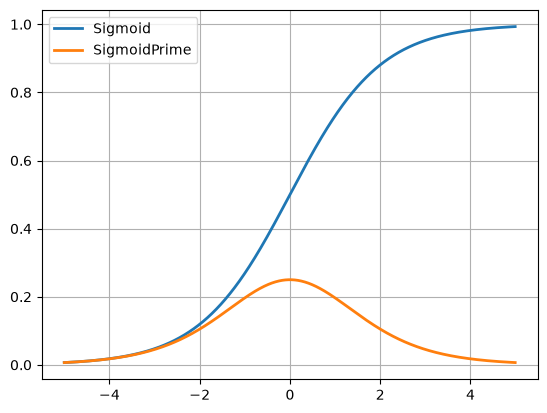

In [907]:
testValues=np.arange(-5,5,0.01)
plt.plot(testValues,NN.sigmoid(testValues),linewidth=2)
plt.plot(testValues, NN.sigmoidPrime(testValues),linewidth=2)
plt.grid(1)
plt.legend(['Sigmoid','SigmoidPrime'])


In [908]:
NN=Neural_Network()

In [909]:
cost1=NN.costFunction(X,y)

In [910]:
cost1

array([0.00899983])

In [911]:
dJdW1,dJdW2=NN.costFunctionPrime(X,y)

In [912]:
dJdW1

array([[-0.00172809, -0.00321991, -0.00203414],
       [ 0.00103511,  0.00145272,  0.00081577]])

In [913]:
dJdW2

array([[-0.00597625],
       [-0.0038706 ],
       [-0.00456626]])

In [914]:
scalar= 3
NN.W1 = NN.W1+scalar*dJdW1
NN.W2 = NN.W2+scalar*dJdW2
cost2 = NN.costFunction(X,y)
print (cost1,cost2)

[0.00899983] [0.00931314]


In [915]:
scalar= 3 #this is our alpha
NN.W1 = NN.W1-scalar*dJdW1
NN.W2 = NN.W2-scalar*dJdW2
cost3 = NN.costFunction(X,y)
print (cost2,cost3)

[0.00931314] [0.00899983]


In [916]:
# NN.W1 = NN.W1 + scalar*(NN.yHat-NN.a3)*NN.sigmoidPrime(NN.z3)*array([NN.X[0,0], NN.X[0,1], NN.X[0,2]],[NN.X[1,0], NN.X[1,1], NN.X[1,2]])
# NN.W1

[[0.94867245 0.29280306 0.67262754]
 [0.45643245 0.49678775 0.88987229]] [[0.64407686]
 [0.93050999]
 [0.66386022]]


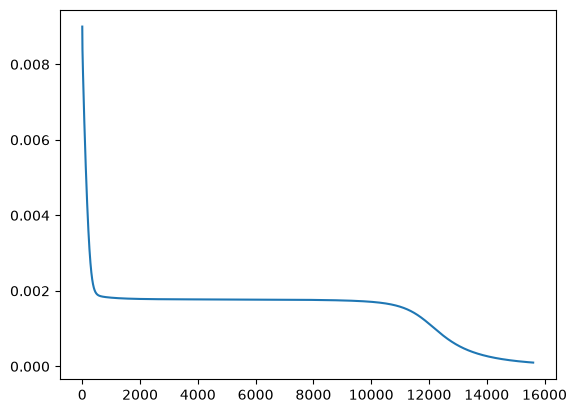

In [917]:
def minimize(alpha, accuracyPoop):
    W1_init = NN.W1
    W2_init = NN.W2
    print(W1_init,W2_init)
    cost = NN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = NN.costFunctionPrime(X, y)

        NN.W1 = NN.W1-alpha*dJdW1
        NN.W2 = NN.W2-alpha*dJdW2

        cost = NN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arr = (minimize(2, .0001))

# print(cost_arr)
plt.plot(cost_arr)

In [918]:
y

array([[0.75],
       [0.8 ],
       [0.93]])

In [919]:
NN.forward(X)

array([[0.74926497],
       [0.80757897],
       [0.91808498]])

In [920]:

class ReluNeural_Network(object):
    def __init__(self):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)


[[0.26935333 0.70285969 0.10449865]
 [0.3674297  0.38973298 0.96592549]] [[0.29274838]
 [0.95108928]
 [0.97477331]]


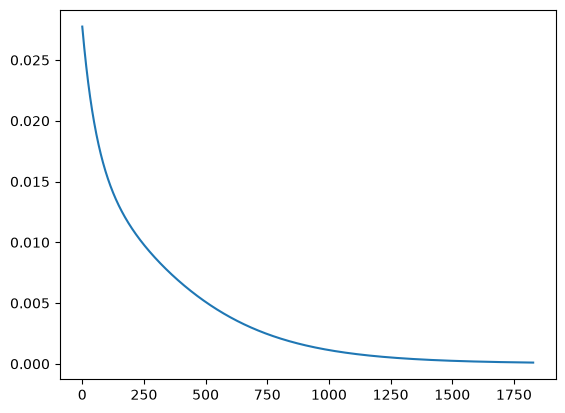

In [921]:
ReluNN = ReluNeural_Network()

def minimizeRelu(alpha, accuracyPoop):
    W1_init = ReluNN.W1
    W2_init = ReluNN.W2
    print(W1_init,W2_init)
    cost = ReluNN.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:

        dJdW1, dJdW2 = ReluNN.costFunctionPrime(X, y)

        ReluNN.W1 = ReluNN.W1-alpha*dJdW1
        ReluNN.W2 = ReluNN.W2-alpha*dJdW2

        cost = ReluNN.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr

cost_arrRelu = (minimizeRelu(.05, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu)

In [922]:
ReluNN.forward(X)-y

array([[ 0.00679949],
       [-0.01208373],
       [-0.00271025]])

In [923]:
class ReluNeural_Network_Extra(object):
    def __init__(self, size):
        #Define Parameters
        self.inputLayerSize = 2
        self.outputLayerSize=1
        self.hiddenLayerSize=3
        self.hiddenLayer_2_Size = size

        #Define Weights
        self.W1=np.random.rand(self.inputLayerSize,self.hiddenLayerSize)
        self.W2=np.random.rand(self.hiddenLayerSize,self.hiddenLayer_2_Size)
        self.W3=np.random.rand(self.hiddenLayer_2_Size,self.outputLayerSize)

    def forward(self,X):
        #Propagate inputs through network
        self.z2 = np.dot(X,self.W1)
        self.a2 = self.relu(self.z2)
        self.z3 = np.dot(self.a2,self.W2)
        self.a3 = self.relu(self.z3)
        self.z4 = np.dot(self.a3, self.W3)
        yHat = self.sigmoid(self.z4)
        return yHat

    def relu(self, z):
        return np.maximum(0, z)

    def reluPrime(self,z):
        return 1 * (z > 0)

    def sigmoid(self, z):
        #Apply Sigmoid Activation Function
        return 1/(1+np.exp(-z))

    def costFunction(self, X, y):
        #Compute Cost Function with weights already stored in class
        self.yHat=self.forward(X)
        J=0.5*sum((y-self.yHat)**2)
        return J


    def costFunctionPrime(self, X, y):
        #Compute derivatives with respect to W1 and W2
        self.yHat=self.forward(X)
        delta4 = np.multiply(-(y-self.yHat), self.sigmoidPrime(self.z4))
        dJdW3=np.dot(self.a3, delta4)
        delta3 = np.multiply(-(y-self.yHat),self.sigmoidPrime(self.z3))
        dJdW2=np.dot(self.a2.T,delta3)
        delta2=np.dot(delta3,self.W2.T)*self.reluPrime(self.z2)
        dJdW1=np.dot(X.T,delta2)
        return dJdW1,dJdW2, dJdW3

    def sigmoidPrime(self,z):
        #Derivative of Sigmoid Function
        return np.exp(-z)/((1+np.exp(-z))**2)



[[0.40719265 0.61474171 0.43065846]
 [0.97517904 0.95853062 0.90665133]] [[0.22682118 0.08597935 0.84050686]
 [0.75424847 0.08565481 0.77421258]
 [0.31820126 0.27715887 0.30438108]]


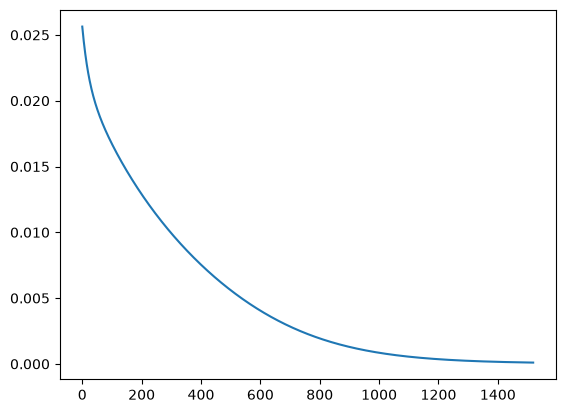

In [924]:
ReluNN_Extra_3 = ReluNeural_Network_Extra(3)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_3.W1
    W2_init = ReluNN_Extra_3.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_3.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_3.costFunctionPrime(X, y)

        ReluNN_Extra_3.W1 = ReluNN_Extra_3.W1 - alpha * dJdW1
        ReluNN_Extra_3.W2 = ReluNN_Extra_3.W2 - alpha * dJdW2
        ReluNN_Extra_3.W3 = ReluNN_Extra_3.W3 - alpha * dJdW3

        cost = ReluNN_Extra_3.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.05, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)


In [925]:
ReluNN_Extra_3.forward(X) - y

array([[ 0.00753063],
       [-0.01169332],
       [-0.00243491]])

In [926]:
ReluNN_Extra_10 = ReluNeural_Network_Extra(10)

def minimizeRelu_Extra(alpha, accuracyPoop):
    W1_init = ReluNN_Extra_10.W1
    W2_init = ReluNN_Extra_10.W2
    print(W1_init, W2_init)
    cost = ReluNN_Extra_10.costFunction(X, y)
    cost_arr = [cost]
    while cost_arr[-1] > accuracyPoop:
        dJdW1, dJdW2, dJdW3 = ReluNN_Extra_10.costFunctionPrime(X, y)

        ReluNN_Extra_10.W1 = ReluNN_Extra_10.W1 - alpha * dJdW1
        ReluNN_Extra_10.W2 = ReluNN_Extra_10.W2 - alpha * dJdW2
        ReluNN_Extra_10.W3 = ReluNN_Extra_10.W3 - alpha * dJdW3

        cost = ReluNN_Extra_10.costFunction(X, y)
        cost_arr.append(cost)

    return cost_arr


cost_arrRelu_Extra = (minimizeRelu_Extra(.05, .0001))

# print(cost_arr)
plt.plot(cost_arrRelu_Extra)



[[0.72843004 0.88727165 0.62163599]
 [0.41618118 0.40066689 0.70880543]] [[0.85636263 0.78104292 0.60895407 0.30567292 0.00395458 0.94815812
  0.1055192  0.77493117 0.44284734 0.26896848]
 [0.04370986 0.4017753  0.90034381 0.77453282 0.76477778 0.3995471
  0.61232157 0.47182598 0.12321798 0.92665582]
 [0.43276907 0.21088929 0.55650155 0.23250391 0.71525469 0.94083563
  0.08136378 0.12304768 0.96127494 0.9149236 ]]


ValueError: shapes (3,10) and (3,1) not aligned: 10 (dim 1) != 3 (dim 0)